# Klike Challenge — Part 2: Predicting the Klike Score

Part 1 left two facts that shape this notebook:

1. **The score rewards creative choices** — hook, face, CTA, subtitles, medium text — and those
   effects hold across platforms, except format.
2. **The score is not only about the creative.** Retargeting lifts CTR and conversions while
   barely touching the score, and completion rate correlates with it strongly — so part of the
   score may be *delivered performance*, measured after launch.

That second point means "a model of the Klike Score" can mean two different products, so this
notebook builds both and keeps them apart:

| Model | Inputs | Answers | Used for |
|---|---|---|---|
| **Creative (pre-flight)** | creative levers + context | *What is this creative worth before any spend?* | the recommendations engine (Part 3) |
| **Full** | the above + CTR, completion rate, conversion rate | *How much of the score is delivered performance?* | diagnosis only — it cannot score an unlaunched ad |

The modelling code lives in `klike/model.py`, so the recommendations engine uses exactly what is
evaluated here. Imputation is inside the sklearn pipelines, so every
cross-validation fold imputes from its own training rows only.

In [1]:
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.linear_model import RidgeCV
from sklearn.model_selection import KFold, RepeatedKFold, cross_validate, train_test_split
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler

from klike.data import load_clean, load_with_recovery
from klike.model import (ALPHAS, LABELS, TARGET, bootstrap, candidate_models, cross_validated_scores,
                         engineer, evaluate, fixed_alpha, make_pipeline)

warnings.filterwarnings("ignore")
pd.set_option("display.width", 160)

df = load_clean()
print(f"{len(df)} campaigns, target mean {df[TARGET].mean():.1f}, sd {df[TARGET].std():.1f}")

500 campaigns, target mean 60.2, sd 15.6


In [2]:
# Chart style, same as in 01_eda: thin marks, light grid, a colourblind-safe palette.
# Platforms always keep the same colour and are labelled directly on the chart.
SURFACE, INK, INK_SOFT, MUTED = "#fcfcfb", "#0b0b0b", "#52514e", "#898781"
GRID, BASELINE = "#e1e0d9", "#c3c2b7"
BLUE, ORANGE, AQUA, RED = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
PLATFORM_COLOURS = {"TikTok": BLUE, "Meta": ORANGE, "LinkedIn": AQUA}


def new_chart(size=(9, 4.2), ncols=1, sharey=False):
    figure, axes = plt.subplots(1, ncols, figsize=size, sharey=sharey)
    figure.patch.set_facecolor(SURFACE)
    for ax in (axes if ncols > 1 else [axes]):
        ax.set_facecolor(SURFACE)
        for spine in ax.spines.values():
            spine.set_visible(False)
        ax.tick_params(colors=MUTED, length=0, labelsize=9)
        for label in ax.get_xticklabels() + ax.get_yticklabels():
            label.set_color(INK_SOFT)
        ax.set_axisbelow(True)
    return figure, axes


def finish(figure, ax, title, subtitle, note, name=None):
    ax.set_title(title, color=INK, fontsize=13, fontweight="bold", loc="left", pad=26)
    ax.annotate(subtitle, xy=(0, 1), xytext=(0, 12), xycoords="axes fraction",
                textcoords="offset points", color=INK_SOFT, fontsize=9.5, va="bottom")
    figure.text(0.01, 0.005, note, color=MUTED, fontsize=7.5, va="bottom")
    figure.tight_layout(rect=(0, 0.03, 1, 1))
    if name:  # saved for the README
        Path("figures").mkdir(exist_ok=True)
        figure.savefig(f"figures/{name}.png", dpi=150, facecolor=SURFACE)
    plt.show()

---
# 1. Feature engineering

## 1.1 What goes in, and why

Features are grouped by **who controls them**, because that decides what each one may be used for:

| Group | Columns | Treatment | Why |
|---|---|---|---|
| Creative levers | `has_hook`, `has_face`, `has_cta`, `has_subtitle`, `text_density`, `format`, `music_voice_ratio`, `video_duration_s` | binaries → 0/1 (unknown → base rate + indicator); categoricals one-hot | the advertiser chooses these; the engine may change them |
| Context | `platform`, `category`, `objective`, `target_audience_age`, `is_retargeting` | one-hot / 0-1 | explain variance; never recommended |
| **Engineered** | `platform_format` = platform × format | one-hot | Part 1: vertical is +9 on TikTok and −12 on LinkedIn. A single `format` coefficient would average those into nothing |
| Performance (full model only) | `log_ctr`, `completion_rate`, `conv_rate` | log10(CTR); avg watch / duration; conversions / clicks | measured after launch |

**Left out on purpose:**

- `campaign_id` — an identifier.
- `impressions`, `clicks`, `spend`, `conversions`, `revenue` — volumes. They measure *budget size*,
  not creative quality; a big campaign is not a better creative.
- `roas` — Part 1 showed no creative lever moves ROAS (it is driven by price and offer), 13% of it is
  missing or untracked, and it adds almost nothing below.
- `avg_watch_time_s` — confounded with duration (a 60s video gets longer watches). `completion_rate`
  is the duration-neutral version.
- `engagement_rate` — its unit is an assumption (basis points), and it adds nothing (tested below).
- `date` — tested below as month-of-launch; no signal.

## 1.2 Testing each engineering decision out of sample

Each candidate feature is judged by what it adds to **cross-validated** R², with 5×5 repeated
folds. In-sample fit always improves when you add a column; only out-of-sample improvement counts.

In [3]:
CV = RepeatedKFold(n_splits=5, n_repeats=5, random_state=42)

X = engineer(df)
X["month"] = X["date"].dt.month.astype(str)
X["hook_x_face"] = X["has_hook"] * X["has_face"]
X["duration_sq"] = X["video_duration_s"] ** 2
X["platform_text"] = X["platform"] + "|" + X["text_density"]
X["ctr_pct"] = X["ctr"] * 100

CREATIVE_NUM = ["has_hook", "has_face", "has_cta", "has_subtitle", "is_retargeting", "music_voice_ratio", "video_duration_s"]
CREATIVE_CAT = ["text_density", "format", "platform", "category", "objective", "target_audience_age"]


def cv_ridge(numeric, categorical):
    pre = ColumnTransformer([
        ("num", Pipeline([("impute", SimpleImputer(strategy="median", add_indicator=True)),
                          ("scale", StandardScaler())]), numeric),
        ("cat", OneHotEncoder(handle_unknown="ignore"), categorical),
    ])
    result = cross_validate(Pipeline([("pre", pre), ("ridge", RidgeCV(alphas=ALPHAS))]),
                            X, X[TARGET], cv=CV, scoring=("r2", "neg_root_mean_squared_error"))
    return result["test_r2"].mean(), -result["test_neg_root_mean_squared_error"].mean()


base = cv_ridge(CREATIVE_NUM, CREATIVE_CAT)
trials = {
    "platform × format  (kept)":  (CREATIVE_NUM, CREATIVE_CAT + ["platform_format"]),
    "platform × text density":    (CREATIVE_NUM, CREATIVE_CAT + ["platform_text"]),
    "hook × face":                (CREATIVE_NUM + ["hook_x_face"], CREATIVE_CAT),
    "duration² (sweet spot)":     (CREATIVE_NUM + ["duration_sq"], CREATIVE_CAT),
    "month of launch":            (CREATIVE_NUM, CREATIVE_CAT + ["month"]),
}
rows = [{"feature added to the creative set": "— creative levers + context —", "CV R²": base[0], "Δ R²": 0.0, "CV RMSE": base[1]}]
for name, (numeric, categorical) in trials.items():
    r2, rmse = cv_ridge(numeric, categorical)
    rows.append({"feature added to the creative set": name, "CV R²": r2, "Δ R²": r2 - base[0], "CV RMSE": rmse})
pd.DataFrame(rows).set_index("feature added to the creative set").round(3)

,CV R²,Δ R²,CV RMSE
feature added to the creative set,,,
— creative levers + context —,0.691,0.000,8.559
platform × format (kept),0.710,0.019,8.278
platform × text density,0.688,-0.002,8.594
hook × face,0.690,-0.001,8.575
duration² (sweet spot),0.691,0.000,8.557
month of launch,0.687,-0.004,8.613


Only **platform × format** earns its place: it is the one interaction Part 1 found, and it
survives out of sample. Hook × face, a duration sweet spot, platform-specific text effects and
seasonality all add nothing — the score is **additive in the creative levers**, which is also why
a linear model will turn out to be the right choice.

For the full model, which performance metrics carry the signal, and on what scale?

In [4]:
WITH_FORMAT = CREATIVE_CAT + ["platform_format"]
base = cv_ridge(CREATIVE_NUM, WITH_FORMAT)
candidates = {
    "CTR (raw %)": "ctr_pct", "CTR (log)": "log_ctr", "completion rate": "completion_rate",
    "conversion rate / click": "conv_rate", "engagement rate": "engagement_rate_frac",
    "ROAS (tracked only)": "roas_valid", "avg watch time (s)": "avg_watch_time_s",
}
rows = []
for name, column in candidates.items():
    r2, _ = cv_ridge(CREATIVE_NUM + [column], WITH_FORMAT)
    rows.append({"performance metric added alone": name, "Δ CV R²": r2 - base[0]})
alone = pd.DataFrame(rows).set_index("performance metric added alone").sort_values("Δ CV R²", ascending=False)

full = cv_ridge(CREATIVE_NUM + ["log_ctr", "completion_rate", "conv_rate"], WITH_FORMAT)
print(f"creative set: R² {base[0]:.3f}  ->  + log CTR, completion, conversion rate: R² {full[0]:.3f}\n")
alone.round(3)

creative set: R² 0.710  ->  + log CTR, completion, conversion rate: R² 0.843



,Δ CV R²
performance metric added alone,
CTR (log),0.109
CTR (raw %),0.066
completion rate,0.013
conversion rate / click,0.011
ROAS (tracked only),0.007
avg watch time (s),0.001
engagement rate,0.000


**CTR is the dominant performance signal, and on a log scale** — the log version adds far more than
raw CTR, which says the score responds to CTR *multiplicatively*: going from 2% to 4% is worth about
as much as 6% to 12%. That matches how marketers think about CTR (relative lifts), and it is the
reason `log_ctr` is the engineered form used.

Completion rate and conversion rate each add a little more; engagement, ROAS and raw watch time add
nothing once CTR is in. The full model uses the three that earn their place.

---
# 2. Choosing the model

Five candidates under the same 5×5 repeated cross-validation: a mean-only baseline, a regularised
linear model (ridge, penalty chosen by internal CV), and two tree ensembles that could find
interactions and non-linearities the linear model cannot.

In [5]:
comparison = cross_validated_scores(candidate_models(), df)
comparison.round(3)

,RMSE,RMSE sd,MAE,R²,R² sd
model,,,,,
Baseline (mean),15.572,0.829,12.584,-0.007,0.008
Ridge · creative,8.278,0.609,6.617,0.710,0.062
Gradient boosting · creative,8.679,0.628,6.948,0.682,0.062
Random forest · creative,9.515,0.568,7.701,0.619,0.064
Ridge · full,6.125,0.374,4.913,0.843,0.024
Gradient boosting · full,6.675,0.434,5.489,0.813,0.030


**Ridge wins in both settings, and the tree models lose to it.** That is informative rather than
disappointing: if there were meaningful interactions or thresholds, gradient boosting would find
them and beat the linear model. It does not, which confirms §1.2 — the score behaves like a sum of
creative effects.

Why ridge specifically, beyond the scores:

- **500 rows, ~40 one-hot columns.** Regularisation keeps the small categories (83 LinkedIn
  campaigns, 11 LinkedIn verticals) from producing wild coefficients.
- **Interpretability is a requirement, not a nicety.** Part 3 must say "a hook is worth +17 points".
  A linear model *is* that statement; a boosted model would need a separate explanation layer that
  approximates it.
- **Counterfactuals are well-behaved.** Changing one lever in a linear model changes the prediction by
  that lever's effect, with no artefacts from tree split points.
- Pragmatism: simplest model that wins.

---
# 3. Evaluation on a held-out test set

Cross-validation chose the model; a final 80/20 split, stratified by score quintile so the test set
contains its share of bad creatives, reports the numbers.

In [6]:
train, test = train_test_split(df, test_size=0.2, random_state=42, stratify=pd.qcut(df[TARGET], 5, labels=False))

creative = make_pipeline("creative").fit(train, train[TARGET])
full_model = make_pipeline("full").fit(train, train[TARGET])
baseline = pd.Series(train[TARGET].mean(), index=test.index)

results = pd.DataFrame({
    "Baseline (train mean)": {"RMSE": ((baseline - test[TARGET]) ** 2).mean() ** 0.5,
                              "MAE": (baseline - test[TARGET]).abs().mean(), "R²": 0.0},
    "Ridge · creative": evaluate(creative, test),
    "Ridge · full": evaluate(full_model, test),
}).T
print(f"test set: {len(test)} campaigns · target sd {test[TARGET].std():.1f}\n")
results.round(3)

test set: 100 campaigns · target sd 15.6



,RMSE,MAE,R²
Baseline (train mean),15.498,12.383,0.000
Ridge · creative,8.651,7.094,0.688
Ridge · full,6.896,5.528,0.802


In [7]:
# How wrong is it, and where? Error by platform and by true-score band.
test_eval = test.assign(
    creative_pred=creative.predict(test), full_pred=full_model.predict(test),
)
test_eval["creative_err"] = test_eval["creative_pred"] - test_eval[TARGET]
test_eval["full_err"] = test_eval["full_pred"] - test_eval[TARGET]

by_platform = test_eval.groupby("platform", observed=True).agg(
    n=(TARGET, "size"),
    creative_MAE=("creative_err", lambda e: e.abs().mean()),
    full_MAE=("full_err", lambda e: e.abs().mean()),
)
bands = pd.cut(test_eval[TARGET], [0, 40, 55, 70, 85, 100], labels=["<40", "40-55", "55-70", "70-85", "85+"])
by_band = test_eval.groupby(bands, observed=True).agg(
    n=(TARGET, "size"),
    creative_bias=("creative_err", "mean"),
    full_bias=("full_err", "mean"),
)
display(by_platform.round(2))
by_band.round(2)

,n,creative_MAE,full_MAE
platform,,,
LinkedIn,20,6.45,6.39
Meta,47,6.81,5.44
TikTok,33,7.90,5.14


,n,creative_bias,full_bias
klike_score,,,
<40,9,10.61,6.17
40-55,27,1.03,1.33
55-70,36,-1.69,-1.25
70-85,25,-6.24,-2.95
85+,3,-8.36,-7.40


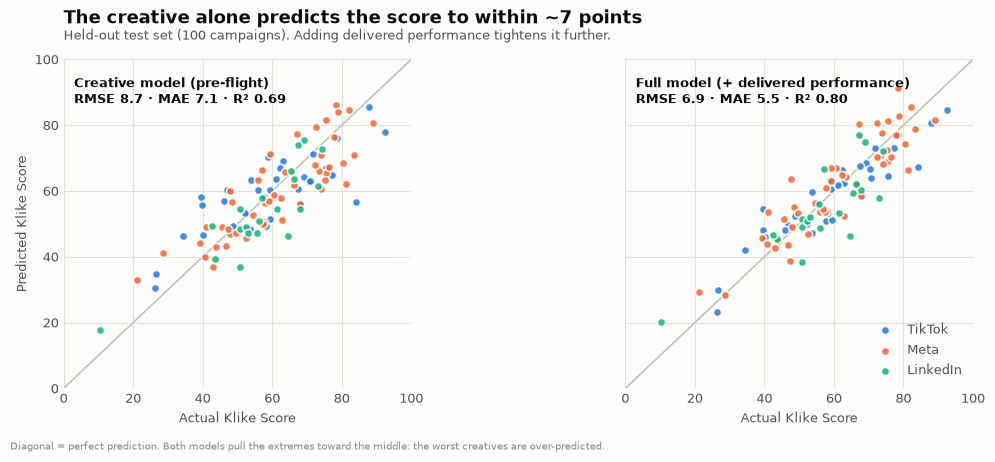

In [8]:
# CHART 1 - predicted vs actual, the two models side by side.
figure, axes = new_chart((10, 4.6), ncols=2, sharey=True)
for ax, column, name, metrics in [
    (axes[0], "creative_pred", "Creative model (pre-flight)", results.loc["Ridge · creative"]),
    (axes[1], "full_pred", "Full model (+ delivered performance)", results.loc["Ridge · full"]),
]:
    for platform, colour in PLATFORM_COLOURS.items():
        part = test_eval[test_eval["platform"] == platform]
        ax.scatter(part[TARGET], part[column], s=34, color=colour, alpha=0.85,
                   edgecolors=SURFACE, linewidths=1.2, label=platform, zorder=3)
    ax.plot([0, 100], [0, 100], color=BASELINE, linewidth=1.2, zorder=2)
    ax.set_xlim(0, 100); ax.set_ylim(0, 100)
    ax.grid(True, color=GRID, linewidth=0.8)
    ax.set_xlabel("Actual Klike Score", color=INK_SOFT, fontsize=9.5)
    ax.text(3, 95, f"{name}\nRMSE {metrics['RMSE']:.1f} · MAE {metrics['MAE']:.1f} · R² {metrics['R²']:.2f}",
            color=INK, fontsize=9.5, va="top", fontweight="bold")
axes[0].set_ylabel("Predicted Klike Score", color=INK_SOFT, fontsize=9.5)
axes[1].legend(frameon=False, fontsize=9, loc="lower right", labelcolor=INK_SOFT)
finish(figure, axes[0],
       "The creative alone predicts the score to within ~7 points",
       "Held-out test set (100 campaigns). Adding delivered performance tightens it further.",
       "Diagonal = perfect prediction. Both models pull the extremes toward the middle: the worst creatives are over-predicted.",
       name="02_predicted_vs_actual")

### What the error means for the product

- **The creative model's typical error is ~7 points on a 0–100 scale** (test MAE 7.1, CV MAE 6.6),
  against ~12.4 for guessing the mean. It explains ~70% of the variance. That is good enough to sort creatives into bands (weak / average / strong) and,
  more importantly for Part 3, to price individual changes — the effect estimates have much tighter
  intervals than individual predictions, because they are averaged over 500 campaigns.
- **It is not good enough to promise a specific score.** "This creative will score 63" carries ±7;
  "adding a hook is worth +17 (CI 16–18)" is far more reliable. The engine is built on the second kind
  of statement.
- **The full model's error drops to ~5.5 (R² 0.80 on test, 0.84 in CV).** Most of what the creative model misses is delivered
  performance, mainly CTR — which the creative partly drives (Part 1: a hook is +68% CTR). This is why
  the engine uses the creative model: it captures a lever's *total* effect, including the part that
  flows through CTR, whereas the full model would only credit the residual direct effect.
- **Both models compress the extremes.** Creatives scoring under 40 are over-predicted by ~10 points
  and those above 70 under-predicted by ~6–8: whatever makes a creative exceptional is partly outside the recorded attributes
  (Part 4 discusses what video features could capture it).

### Would dropping the corrupted rows have mattered?

Part 1 refused to drop the 16 targets damaged by Excel, because they were almost all of the worst
creatives. Here is the measured cost of the shortcut: the same model trained without them, evaluated
out-of-fold on everything.

In [9]:
_, recovered_mask = load_with_recovery()
corrupted = recovered_mask[TARGET].to_numpy()
worst_decile = (df[TARGET] <= df[TARGET].quantile(0.10)).to_numpy()

records = {"kept (this project)": [], "dropped (naive cleaning)": []}
for seed in range(5):
    out_of_fold = {name: np.zeros(len(df)) for name in records}
    for train_idx, test_idx in KFold(5, shuffle=True, random_state=seed).split(df):
        fold = df.iloc[train_idx]
        out_of_fold["kept (this project)"][test_idx] = make_pipeline().fit(fold, fold[TARGET]).predict(df.iloc[test_idx])
        fold = fold[~corrupted[train_idx]]
        out_of_fold["dropped (naive cleaning)"][test_idx] = make_pipeline().fit(fold, fold[TARGET]).predict(df.iloc[test_idx])
    for name, predicted in out_of_fold.items():
        error = predicted - df[TARGET].to_numpy()
        records[name].append({
            "bias on worst 10%": error[worst_decile].mean(),
            "RMSE on worst 10%": np.sqrt((error[worst_decile] ** 2).mean()),
            "RMSE overall": np.sqrt((error ** 2).mean()),
        })
pd.DataFrame({name: pd.DataFrame(r).mean() for name, r in records.items()}).T.round(2)

,bias on worst 10%,RMSE on worst 10%,RMSE overall
kept (this project),9.22,12.42,8.31
dropped (naive cleaning),10.82,13.47,8.40


Overall RMSE barely moves — which is exactly why the damage would go unnoticed. But on the worst
10% of creatives the naive model becomes **more optimistic** and less accurate. For a product whose
job is to tell people their creative is weak, that is the wrong direction to be wrong in.

---
# 4. Feature importance

Two complementary views:

1. **Effect sizes in score points**, with bootstrap 95% intervals — *what is each choice worth?*
   This is the business-facing view and what the engine quotes.
2. **Permutation importance** on the test set — *how much does the model rely on each input?*
   This also accounts for how often a feature varies, not just its effect size.

## 4.1 What each creative choice is worth

In [10]:
final = make_pipeline("creative").fit(df, df[TARGET])
boots = bootstrap(fixed_alpha(final), df, n=200, seed=0)


def effect(model, rows, change_to, change_from):
    return (model.predict(rows.assign(**change_to)) - model.predict(rows.assign(**change_from))).mean()


tiktok, meta, linkedin = (df[df["platform"] == p] for p in ["TikTok", "Meta", "LinkedIn"])
CONTRASTS = [
    ("Hook in first 3s", "lever", df, {"has_hook": True}, {"has_hook": False}),
    ("Text density: medium vs high", "lever", df, {"text_density": "medium"}, {"text_density": "high"}),
    ("Human face on screen", "lever", df, {"has_face": True}, {"has_face": False}),
    ("Subtitles", "lever", df, {"has_subtitle": True}, {"has_subtitle": False}),
    ("Call to action", "lever", df, {"has_cta": True}, {"has_cta": False}),
    ("Text density: low vs high", "lever", df, {"text_density": "low"}, {"text_density": "high"}),
    ("Voice-led audio (ratio 0.2 vs 0.6)", "lever", df, {"music_voice_ratio": 0.2}, {"music_voice_ratio": 0.6}),
    ("Duration 15s vs 45s", "lever", df, {"video_duration_s": 15.0}, {"video_duration_s": 45.0}),
    ("Vertical vs square · TikTok", "format", tiktok, {"format": "vertical"}, {"format": "quadrado"}),
    ("Square vs horizontal · Meta", "format", meta, {"format": "quadrado"}, {"format": "horizontal"}),
    ("Vertical vs horizontal · LinkedIn", "format", linkedin, {"format": "vertical"}, {"format": "horizontal"}),
    ("Retargeting audience", "context", df, {"is_retargeting": True}, {"is_retargeting": False}),
    ("Platform: TikTok vs LinkedIn (same square video)", "context", df, {"platform": "TikTok", "format": "quadrado"}, {"platform": "LinkedIn", "format": "quadrado"}),
]
rows = []
for name, group, rows_, to, frm in CONTRASTS:
    draws = np.array([effect(b, rows_, to, frm) for b in boots])
    rows.append({"contrast": name, "group": group, "points": effect(final, rows_, to, frm),
                 "ci_low": np.percentile(draws, 2.5), "ci_high": np.percentile(draws, 97.5)})
effects = pd.DataFrame(rows)
effects.set_index("contrast").round(1)

,group,points,ci_low,ci_high
contrast,,,,
Hook in first 3s,lever,17.1,15.6,18.4
Text density: medium vs high,lever,13.5,11.3,15.4
Human face on screen,lever,11.8,10.1,13.0
Subtitles,lever,8.3,6.8,9.6
Call to action,lever,8.1,6.5,9.5
Text density: low vs high,lever,6.8,4.6,8.7
Voice-led audio (ratio 0.2 vs 0.6),lever,1.9,0.4,3.5
Duration 15s vs 45s,lever,0.5,-1.2,2.8
Vertical vs square · TikTok,format,3.4,0.1,6.6


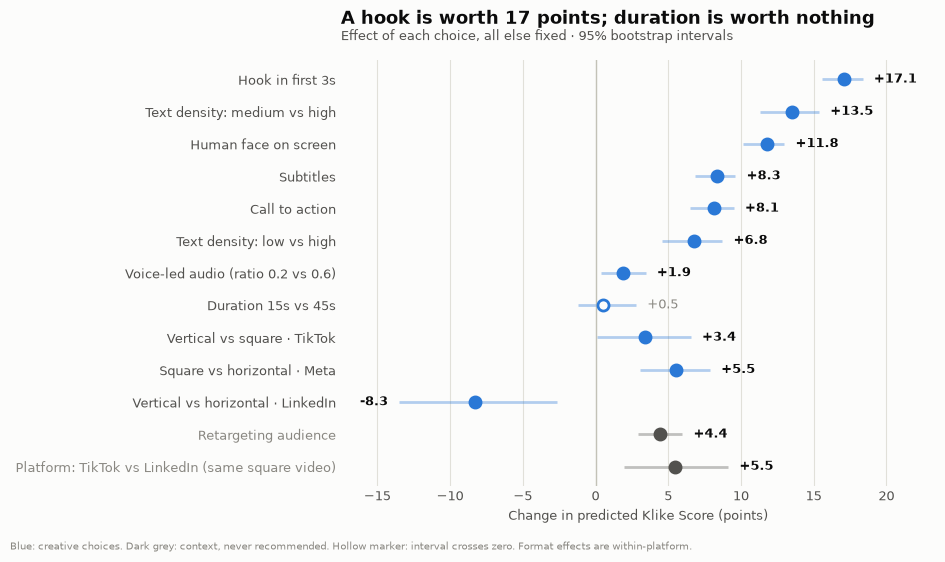

In [11]:
# CHART 2 - the price list: what each choice is worth, in points.
plot = effects.iloc[::-1].reset_index(drop=True)
figure, ax = new_chart((9.5, 5.6))
colour_of = {"lever": BLUE, "format": BLUE, "context": INK_SOFT}
for i, row in plot.iterrows():
    significant = row["ci_low"] > 0 or row["ci_high"] < 0
    colour = colour_of[row["group"]]
    ax.hlines(i, row["ci_low"], row["ci_high"], color=colour, linewidth=2, alpha=0.35)
    ax.scatter(row["points"], i, s=64, zorder=3, linewidths=2,
               color=colour if significant else SURFACE, edgecolors=colour)
    negative = row["points"] < 0
    ax.annotate(f"{row['points']:+.1f}", xy=(row["ci_low"] if negative else row["ci_high"], i),
                xytext=(-8 if negative else 8, 0), textcoords="offset points",
                ha="right" if negative else "left", va="center", fontsize=9,
                color=INK if significant else MUTED, fontweight="bold" if significant else "normal")
ax.axvline(0, color=BASELINE, linewidth=1)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_yticks(range(len(plot)), plot["contrast"])
for label, group in zip(ax.get_yticklabels(), plot["group"]):
    label.set_color(MUTED if group == "context" else INK_SOFT)
ax.set_xlabel("Change in predicted Klike Score (points)", color=INK_SOFT, fontsize=9.5)
ax.set_xlim(plot["ci_low"].min() - 4, plot["ci_high"].max() + 5)
finish(figure, ax,
       "A hook is worth 17 points; duration is worth nothing",
       "Effect of each choice, all else fixed · 95% bootstrap intervals",
       "Blue: creative choices. Dark grey: context, never recommended. Hollow marker: interval crosses zero. Format effects are within-platform.",
       name="02_effect_sizes")

## 4.2 What the models rely on

In [12]:
def permutation_rmse(model, frame, columns, n_repeats=30, seed=0):
    # Increase in RMSE when each *model input* is shuffled. Shuffling happens after feature
    # engineering, so derived inputs (log CTR, conversion rate) are shuffled as the model sees
    # them: shuffling raw `conversions` against another row's `clicks` would invent impossible
    # conversion rates. platform_format is re-derived when its parts move.
    rng = np.random.default_rng(seed)
    engineered = engineer(frame)
    head = model[1:]                       # preprocess + ridge, skipping the engineer step
    rmse = lambda X: np.sqrt(((head.predict(X) - frame[TARGET].to_numpy()) ** 2).mean())
    reference = rmse(engineered)
    out = {}
    for column in columns:
        if column not in engineered:
            continue
        increases = []
        for _ in range(n_repeats):
            shuffled = engineered.copy()
            shuffled[column] = rng.permutation(shuffled[column].to_numpy())
            shuffled["platform_format"] = shuffled["platform"] + "|" + shuffled["format"]
            increases.append(rmse(shuffled) - reference)
        out[column] = np.mean(increases)
    return pd.Series(out)


columns = ["has_hook", "has_face", "has_cta", "has_subtitle", "is_retargeting", "music_voice_ratio",
           "video_duration_s", "text_density", "format", "platform", "category", "objective",
           "target_audience_age", "log_ctr", "completion_rate", "conv_rate"]
importance = pd.DataFrame({
    "creative model": permutation_rmse(creative, test, columns),
    "full model": permutation_rmse(full_model, test, columns),
}).reindex(columns).fillna(0)
importance.index = [LABELS.get(c, c).replace("CTR (log)", "CTR") for c in importance.index]
importance.sort_values("full model", ascending=False).round(2)

,creative model,full model
Hook in first 3s,6.16,4.52
Human face on screen,3.36,2.99
CTR,0.00,2.86
On-screen text density,2.11,1.96
Subtitles,1.62,1.55
Call to action,1.34,1.53
Conversion rate per click,0.00,1.19
Platform,1.01,1.10
Video format,0.69,0.91
Completion rate,0.00,0.66


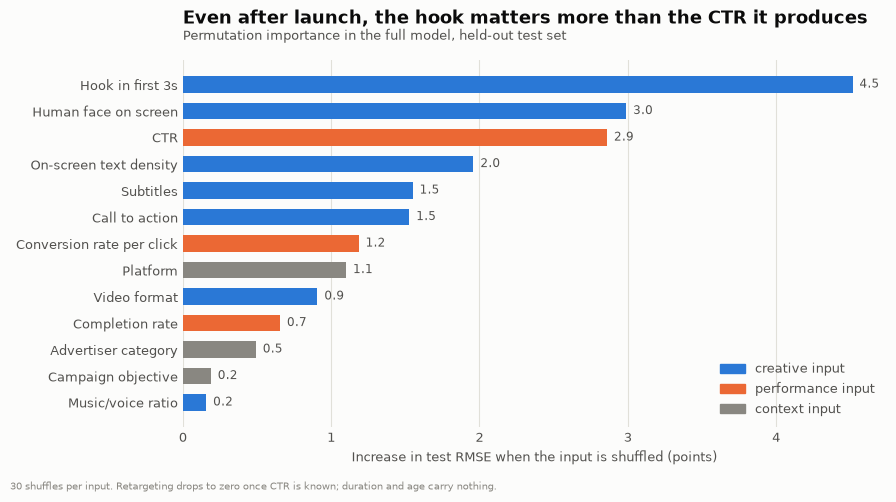

In [13]:
# CHART 3 - where the full model's accuracy comes from, by who controls the input.
GROUP = {
    "CTR": "performance", "Completion rate": "performance", "Conversion rate per click": "performance",
    "Platform": "context", "Advertiser category": "context", "Campaign objective": "context",
    "Audience age": "context", "Retargeting audience": "context",
}
plot = importance.sort_values("full model")
plot = plot[plot["full model"] > 0.05]
colours = {"creative": BLUE, "performance": ORANGE, "context": MUTED}

figure, ax = new_chart((9, 5))
for i, (name, row) in enumerate(plot.iterrows()):
    group = GROUP.get(name, "creative")
    ax.barh(i, row["full model"], height=0.62, color=colours[group], zorder=3)
    ax.annotate(f"{row['full model']:.1f}", xy=(row["full model"], i), xytext=(5, 0),
                textcoords="offset points", va="center", fontsize=8.5, color=INK_SOFT)
ax.set_yticks(range(len(plot)), plot.index)
ax.xaxis.grid(True, color=GRID, linewidth=0.8)
ax.set_xlabel("Increase in test RMSE when the input is shuffled (points)", color=INK_SOFT, fontsize=9.5)
ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=c, label=f"{g} input") for g, c in colours.items()],
          frameon=False, fontsize=9, loc="lower right", labelcolor=INK_SOFT)
finish(figure, ax,
       "Even after launch, the hook matters more than the CTR it produces",
       "Permutation importance in the full model, held-out test set",
       "30 shuffles per input. Retargeting drops to zero once CTR is known; duration and age carry nothing.",
       name="02_permutation_importance")

## 4.3 Does it make business sense?

**Yes — and where it is surprising, the surprise is informative.**

- **Hook (+17) is the biggest creative lever.** Feeds are scrolled, not watched; the first three
  seconds decide whether anything after them is seen. Part 1 found the same lever lifts CTR +68% and
  conversions +33%, so the score and the business metrics agree.
- **Medium text beats both extremes (+13 vs high, +7 vs low).** Some on-screen text carries the
  message for sound-off viewing; a wall of text competes with the video. The non-monotonic shape is
  something a "less text is better" rule would get wrong.
- **Face (+12), subtitles (+8), CTA (+8)** are the standard creative best practices — human presence,
  sound-off legibility, and telling the viewer what to do next. The model rediscovered them from data.
- **Voice-led audio helps a little (~+2 for 0.6 → 0.2).** Real, small: a polish step.
- **Format matters only relative to the platform.** Native formats win (vertical on TikTok, horizontal
  on LinkedIn); the engineered `platform_format` feature is what lets the model say so.
- **Duration is worth nothing to the score.** Part 1 found a modest TikTok CTR sweet spot, and the
  engine uses it for CTR — but the score itself is indifferent to length.
- **Context matters less than the creative.** The same square video scores ~5 points higher on TikTok
  than on LinkedIn; category and objective move it less, and audience age not at all. That is a *good*
  property for a creative-quality score: two identical videos should score about the same whoever runs
  them, and here the creative levers outweigh context several times over.
- **Retargeting is the one surprise: ~+4 points with the creative held fixed** (Part 1's raw
  comparison was +2.6 and not significant, because retargeted creatives happen to be slightly weaker).
  And its importance **drops to zero in the full model** — once CTR is known, retargeting adds
  nothing. So the score absorbs some audience quality *through CTR*: a retargeted audience clicks more,
  and the score rewards the clicks. It is a context variable,
  so the engine never recommends it as a creative fix — but it is worth flagging to the Klike team as a
  possible leak of audience effects into a creative score.
- **In the full model, CTR becomes the third most important input**, behind only the hook and the face,
  and log CTR alone is worth +0.11 R². The Klike Score is partly a performance score. That is fine for
  evaluating a launched campaign, but it means a pre-flight score must come from the creative model.

---
# 5. Summary of Part 2

| | Creative model (pre-flight) | Full model |
|---|---|---|
| Inputs | creative levers + context + platform×format | + log CTR, completion, conversion rate |
| Algorithm | Ridge (alpha by internal CV) | Ridge |
| CV R² (5×5) | 0.71 ± 0.06 | 0.84 ± 0.02 |
| CV RMSE / MAE | 8.3 / 6.6 points | 6.1 / 4.9 points |
| Test R² · RMSE · MAE (n=100) | 0.69 · 8.7 · 7.1 | 0.80 · 6.9 · 5.5 |
| Use | scoring before launch; **the engine's model** | diagnosis after launch |

Tree ensembles were tried and lost: the score is additive in the creative attributes, so the
simplest interpretable model is also the most accurate one.